In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model, plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf

from numpy.lib.stride_tricks import sliding_window_view

<h1> Import Data

Text(0.5, 0.98, 'All Data')

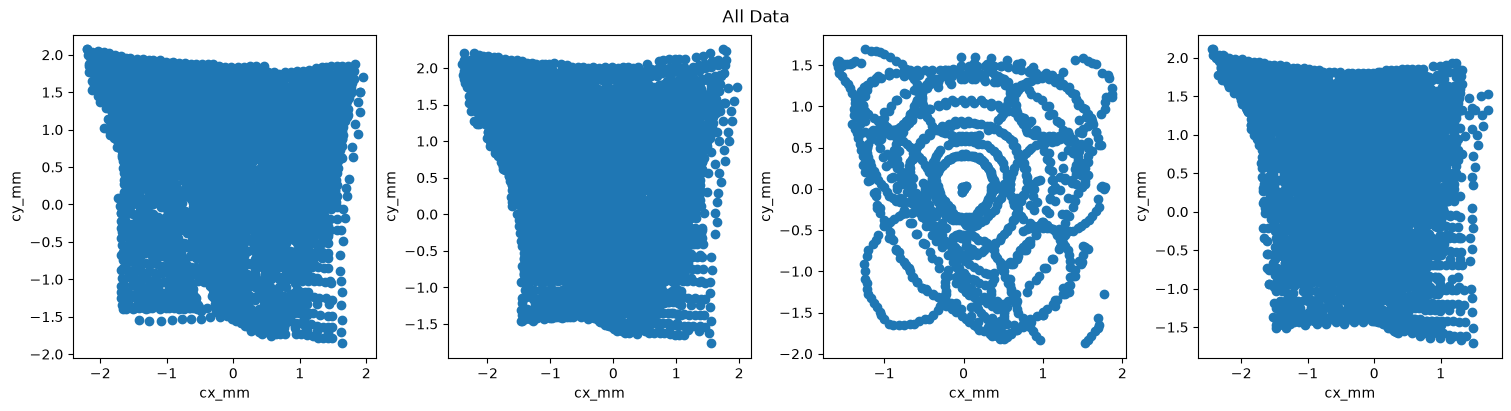

In [3]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64

#remove nans
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()

data_list = [data_0, data_1, data_2, data_3]

fig, axs = plt.subplots(1, 4, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
fig.suptitle("All Data")

<h2>Concatenate

In [4]:
all_data = pd.concat(data_list, ignore_index=True)

<h2> Create StandardScalers based on all data

In [5]:
scalerX = StandardScaler().fit(all_data[["cx_mm", "cy_mm"]])
scalerY = StandardScaler().fit(all_data[["s0", "s1", "s2"]])

<h2>Scale all datasets

In [6]:
scaled = {}
for i, data in enumerate(data_list):
    scaled[f"X_scaled_{i}"] = scalerX.transform(data[["cx_mm", "cy_mm"]])
    scaled[f"y_scaled_{i}"] = scalerY.transform(data[["s0", "s1", "s2"]])

In [10]:
X_scaled_all = scalerX.transform(all_data[["cx_mm", "cy_mm"]])
y_scaled_all = scalerY.transform(all_data[["s0", "s1", "s2"]])
# plt.scatter(X_scaled_all[:,0], X_scaled_all[:,1])

<h2> Build Model

In [7]:
model = build_nn_model(6, 9)
model.summary() #investigate

W0000 00:00:1794391726.893533 2632005 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,985 (27.29 KB)

 Trainable params: 6,985 (27.29 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

<h3>Windows

In [18]:
scores = []

inputs = X_scaled_all
outputs = y_scaled_all

WINDOW_LEN = 3

cx_mm = inputs[:, 0].reshape(-1, 1)
cy_mm = inputs[:,1].reshape(-1, 1)

# create position windows...
cx_mm_window = sliding_window_view(cx_mm, WINDOW_LEN, 0).squeeze()
cy_mm_window = sliding_window_view(cy_mm, WINDOW_LEN, 0).squeeze()

cxcy_window = np.concatenate([cx_mm_window, cy_mm_window], axis=1)
cxcy_window = (cxcy_window)

print(f"Original input (position only): {inputs.shape}")
print(f"New input (position history): {cxcy_window.shape}")

#create voltage windows
s0 = outputs[:,0].reshape(-1, 1)
s1 = outputs[:,1].reshape(-1, 1)
s2 = outputs[:,2].reshape(-1, 1)

# create position windows...
s0_window = sliding_window_view(s0, WINDOW_LEN, 0).squeeze()
s1_window = sliding_window_view(s1, WINDOW_LEN, 0).squeeze()
s2_window = sliding_window_view(s2, WINDOW_LEN, 0).squeeze()

s0s1s2_window = np.concatenate([s0_window, s1_window, s2_window], axis=1)
s0s1s2_window = (s0s1s2_window)

print(s0s1s2_window)
print(f"Original output (motors only): {outputs.shape}")
print(f"New input (motors history): {s0s1s2_window.shape}")

Original input (position only): (12659, 2)
New input (position history): (12657, 6)
[[-0.00772523 -0.00772523  1.7483078  ... -0.0017628  -0.0017628
   0.6401474 ]
 [-0.00772523  1.7483078   1.7483078  ... -0.0017628   0.6401474
   0.5134208 ]
 [ 1.7483078   1.7483078   1.7483078  ...  0.6401474   0.5134208
   0.38697964]
 ...
 [ 1.4556357   1.4556357   1.4556357  ...  0.279947    0.40667364
   0.5331148 ]
 [ 1.4556357   1.4556357  -0.00772523 ...  0.40667364  0.5331148
  -0.0017628 ]
 [ 1.4556357  -0.00772523 -0.00772523 ...  0.5331148  -0.0017628
  -0.0017628 ]]
Original output (motors only): (12659, 3)
New input (motors history): (12657, 9)


<h2>TimeSeriesSplit


Fold: 0 Results (scaled):
  Overall R2:  0.9630
  Weighted R2: 0.9617

Fold: 1 Results (scaled):
  Overall R2:  0.9391
  Weighted R2: 0.9430

Fold: 2 Results (scaled):
  Overall R2:  0.9538
  Weighted R2: 0.9535
MSE scores for each fold: [0.03633660823106766, 0.05786280333995819, 0.044098254293203354]


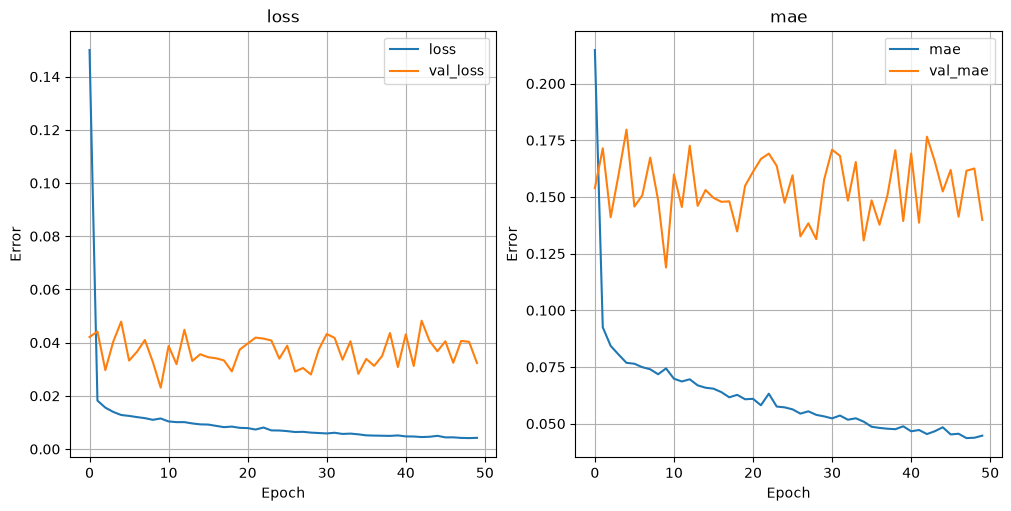

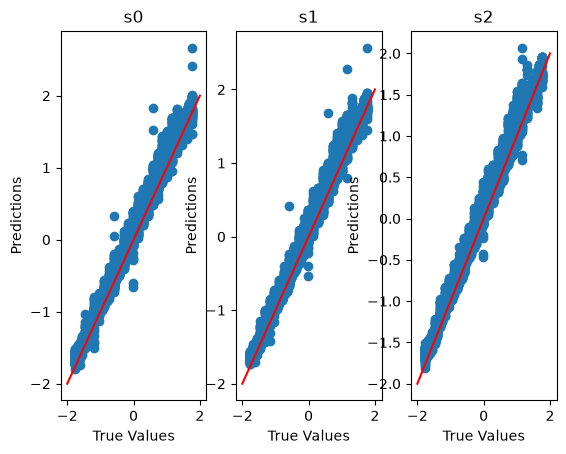

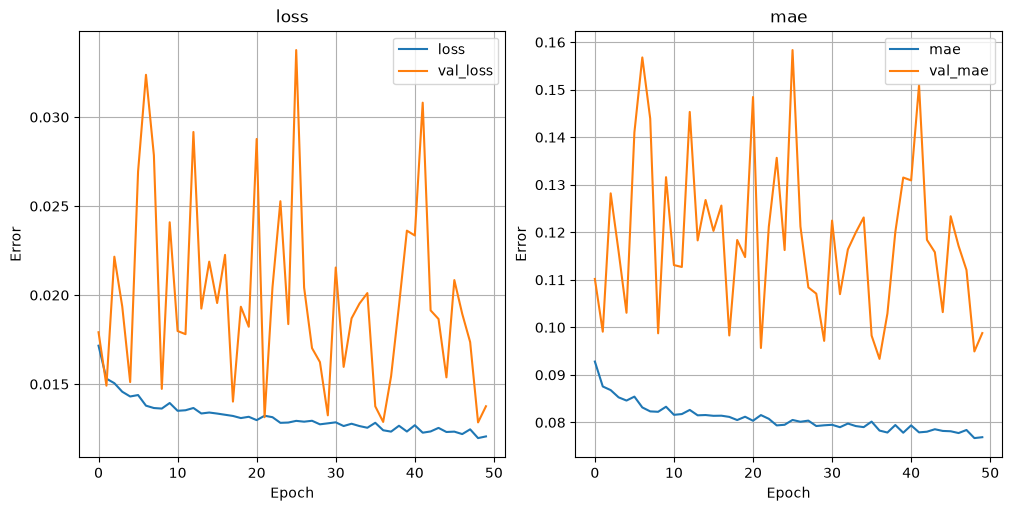

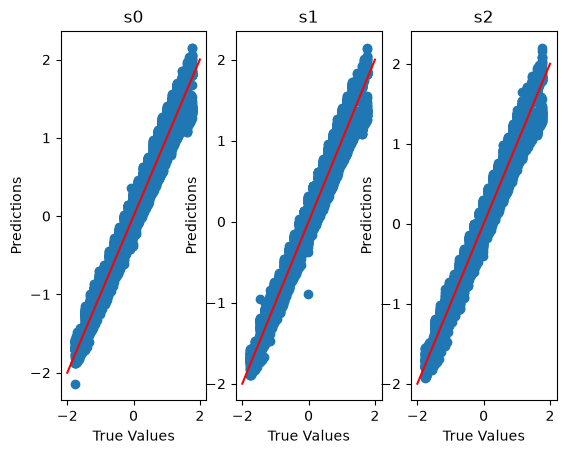

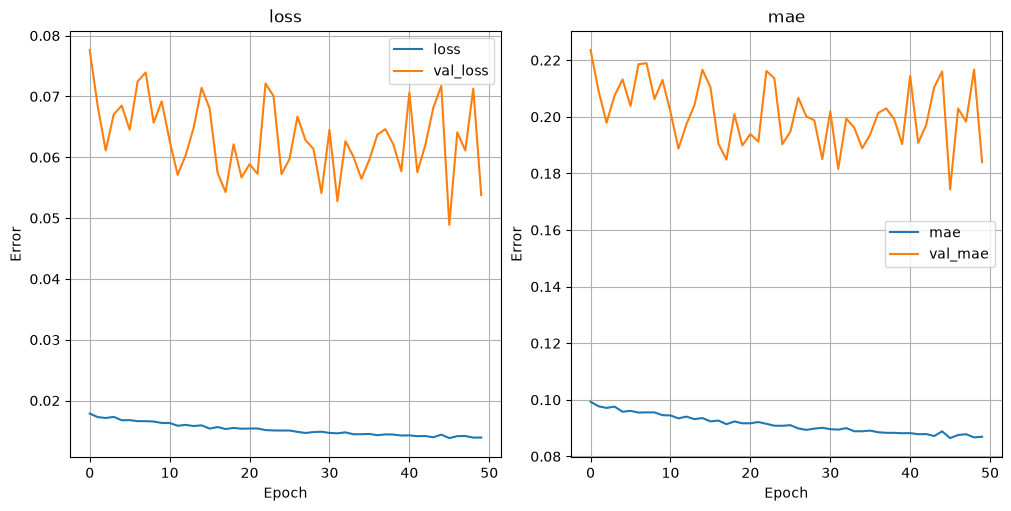

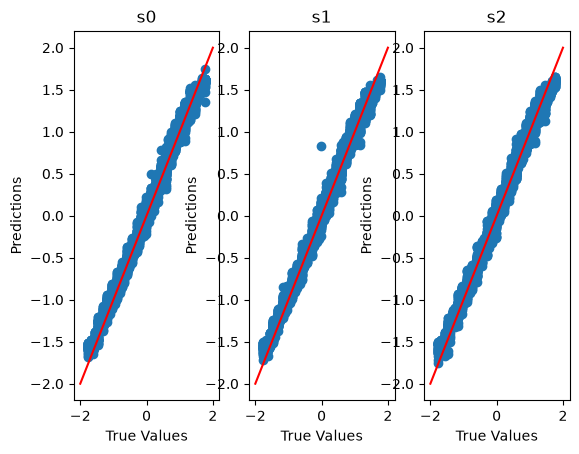

In [19]:
X = cxcy_window
y = s0s1s2_window


tscv = TimeSeriesSplit(n_splits=3)
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    # print(f"Fold {i}:")
    # print(f"  Train: index={train_index}")
    # print(f"  Test:  index={test_index}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    history = train_model(model, X_train, y_train, verbose=0, epochs=50)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plot_loss_and_mae(history)
    plot_motors(y_test, y_pred, [-2,2])

print("MSE scores for each fold:", scores)

In [ ]:

y = scaled["data_0_y_scaled"]
